# Pizza Restaurant Sales Analysis

One year (2015) of orders from a pizza restaurant. I used **SQL** to answer the business questions and **Python (pandas, Matplotlib)** to load the data and make charts.

Questions:
- How much do we sell, and how big is a typical order?
- When are we busiest (hour of the day, day of the week)?
- Which pizzas sell best and worst?

Data: Pizza Place Sales from the Maven Analytics data playground. 4 tables: `orders` (date and time of each order), `order_details` (pizzas in each order), `pizzas` (size and price), `pizza_types` (name and category).

## Load and check the data

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

orders = pd.read_csv("orders.csv")
order_details = pd.read_csv("order_details.csv")
pizzas = pd.read_csv("pizzas.csv")
pizza_types = pd.read_csv("pizza_types.csv", encoding="latin-1")

print("orders:", orders.shape)
print("order_details:", order_details.shape)
print("pizzas:", pizzas.shape)
print("pizza_types:", pizza_types.shape)

orders: (21350, 3)
order_details: (48620, 4)
pizzas: (96, 4)
pizza_types: (32, 4)


In [2]:
orders.head()

,order_id,date,time
0,1,2015-01-01,11:38:36
1,2,2015-01-01,11:57:40
2,3,2015-01-01,12:12:28
3,4,2015-01-01,12:16:31
4,5,2015-01-01,12:21:30


In [3]:
order_details.head()

,order_details_id,order_id,pizza_id,quantity
0,1,1,hawaiian_m,1
1,2,2,classic_dlx_m,1
2,3,2,five_cheese_l,1
3,4,2,ital_supr_l,1
4,5,2,mexicana_m,1


Checking for missing values, duplicates, and pizzas or orders that don't exist in the other tables:

In [4]:
print("missing values:", orders.isnull().sum().sum() + order_details.isnull().sum().sum())
print("duplicate order ids:", orders["order_id"].duplicated().sum())
print("unknown pizza ids:", (~order_details["pizza_id"].isin(pizzas["pizza_id"])).sum())
print("unknown order ids:", (~order_details["order_id"].isin(orders["order_id"])).sum())
print("dates:", orders["date"].min(), "to", orders["date"].max())

missing values: 0
duplicate order ids: 0
unknown pizza ids: 0
unknown order ids: 0
dates: 2015-01-01 to 2015-12-31


The data is clean. (The pizza_types file has special characters, so I read it with `encoding="latin-1"`.)

I add month, hour and weekday columns to make the SQL simpler, then load the tables into SQLite.

In [5]:
order_time = pd.to_datetime(orders["date"] + " " + orders["time"])
orders["month"] = order_time.dt.strftime("%Y-%m")
orders["hour"] = order_time.dt.hour
orders["weekday"] = order_time.dt.day_name()

conn = sqlite3.connect(":memory:")
orders.to_sql("orders", conn, index=False)
order_details.to_sql("order_details", conn, index=False)
pizzas.to_sql("pizzas", conn, index=False)
pizza_types.to_sql("pizza_types", conn, index=False)

def run(query):
    return pd.read_sql(query, conn)

## Analysis with SQL
The same queries are saved in `queries.sql`.

### 1. Overall numbers
Revenue = quantity × price, so order_details has to be joined with pizzas.

In [6]:
kpi = run("""
SELECT COUNT(DISTINCT od.order_id)                                   AS total_orders,
       SUM(od.quantity)                                              AS pizzas_sold,
       ROUND(SUM(od.quantity * p.price))                             AS revenue,
       ROUND(SUM(od.quantity * p.price) / COUNT(DISTINCT od.order_id), 2) AS avg_order_value,
       ROUND(1.0 * SUM(od.quantity) / COUNT(DISTINCT od.order_id), 2) AS pizzas_per_order
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id;
""")
kpi

,total_orders,pizzas_sold,revenue,avg_order_value,pizzas_per_order
0,21350,49574,817860.0,38.31,2.32


### 2. Revenue by month, and change from last month (LAG)

In [7]:
monthly = run("""
WITH monthly AS (
    SELECT o.month,
           SUM(od.quantity * p.price) AS revenue
    FROM orders o
    JOIN order_details od ON o.order_id = od.order_id
    JOIN pizzas p         ON od.pizza_id = p.pizza_id
    GROUP BY o.month
)
SELECT month,
       ROUND(revenue) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS change_pct
FROM monthly
ORDER BY month;
""")
monthly

,month,revenue,change_pct
0,2015-01,69793.0,NaN
1,2015-02,65160.0,-6.6
2,2015-03,70397.0,8.0
3,2015-04,68737.0,-2.4
4,2015-05,71403.0,3.9
5,2015-06,68230.0,-4.4
6,2015-07,72558.0,6.3
7,2015-08,68278.0,-5.9
8,2015-09,64180.0,-6.0
9,2015-10,64028.0,-0.2


### 3. Busiest hours of the day

In [8]:
hourly = run("""
SELECT hour,
       COUNT(*) AS orders
FROM orders
GROUP BY hour
ORDER BY hour;
""")
hourly

,hour,orders
0,9,1
1,10,8
2,11,1231
3,12,2520
4,13,2455
5,14,1472
6,15,1468
7,16,1920
8,17,2336
9,18,2399


### 4. Busiest days of the week
Some weekdays appear more times in the year than others, so I compare the average orders per day, not just the total.

In [9]:
weekday = run("""
SELECT weekday,
       COUNT(*)                                    AS orders,
       ROUND(1.0 * COUNT(*) / COUNT(DISTINCT date), 1) AS avg_orders_per_day
FROM orders
GROUP BY weekday
ORDER BY avg_orders_per_day DESC;
""")
weekday

,weekday,orders,avg_orders_per_day
0,Friday,3538,70.8
1,Thursday,3239,62.3
2,Saturday,3158,60.7
3,Wednesday,3024,58.2
4,Monday,2794,58.2
5,Tuesday,2973,57.2
6,Sunday,2624,50.5


### 5. Sales by pizza category, with share of total (CTE + subquery)

In [10]:
category = run("""
WITH category_sales AS (
    SELECT t.category,
           SUM(od.quantity)            AS pizzas_sold,
           SUM(od.quantity * p.price)  AS revenue
    FROM order_details od
    JOIN pizzas p       ON od.pizza_id = p.pizza_id
    JOIN pizza_types t  ON p.pizza_type_id = t.pizza_type_id
    GROUP BY t.category
)
SELECT category,
       pizzas_sold,
       ROUND(revenue) AS revenue,
       ROUND(100.0 * revenue / (SELECT SUM(revenue) FROM category_sales), 1) AS revenue_share_pct
FROM category_sales
ORDER BY revenue DESC;
""")
category

,category,pizzas_sold,revenue,revenue_share_pct
0,Classic,14888,220053.0,26.9
1,Supreme,11987,208197.0,25.5
2,Chicken,11050,195920.0,24.0
3,Veggie,11649,193690.0,23.7


### 6. Sales by pizza size

In [11]:
sizes = run("""
SELECT p.size,
       SUM(od.quantity)                  AS pizzas_sold,
       ROUND(SUM(od.quantity * p.price)) AS revenue
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id
GROUP BY p.size
ORDER BY revenue DESC;
""")
sizes

,size,pizzas_sold,revenue
0,L,18956,375319.0
1,M,15635,249382.0
2,S,14403,178077.0
3,XL,552,14076.0
4,XXL,28,1007.0


### 7. Top 3 pizzas in each category (ROW_NUMBER)

In [12]:
top3 = run("""
WITH pizza_sales AS (
    SELECT t.category,
           t.name,
           ROUND(SUM(od.quantity * p.price)) AS revenue
    FROM order_details od
    JOIN pizzas p       ON od.pizza_id = p.pizza_id
    JOIN pizza_types t  ON p.pizza_type_id = t.pizza_type_id
    GROUP BY t.category, t.name
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY category ORDER BY revenue DESC) AS rank_in_category
    FROM pizza_sales
)
SELECT category, rank_in_category, name, revenue
FROM ranked
WHERE rank_in_category <= 3
ORDER BY category, rank_in_category;
""")
top3

,category,rank_in_category,name,revenue
0,Chicken,1,The Thai Chicken Pizza,43434.0
1,Chicken,2,The Barbecue Chicken Pizza,42768.0
2,Chicken,3,The California Chicken Pizza,41410.0
3,Classic,1,The Classic Deluxe Pizza,38181.0
4,Classic,2,The Hawaiian Pizza,32273.0
5,Classic,3,The Pepperoni Pizza,30162.0
6,Supreme,1,The Spicy Italian Pizza,34831.0
7,Supreme,2,The Italian Supreme Pizza,33477.0
8,Supreme,3,The Sicilian Pizza,30941.0
9,Veggie,1,The Four Cheese Pizza,32266.0


### 8. Bottom 5 pizzas by revenue

In [13]:
bottom5 = run("""
SELECT t.name,
       SUM(od.quantity)                  AS pizzas_sold,
       ROUND(SUM(od.quantity * p.price)) AS revenue
FROM order_details od
JOIN pizzas p       ON od.pizza_id = p.pizza_id
JOIN pizza_types t  ON p.pizza_type_id = t.pizza_type_id
GROUP BY t.name
ORDER BY revenue ASC
LIMIT 5;
""")
bottom5

,name,pizzas_sold,revenue
0,The Brie Carre Pizza,490,11589.0
1,The Green Garden Pizza,997,13956.0
2,The Spinach Supreme Pizza,950,15278.0
3,The Mediterranean Pizza,934,15361.0
4,The Spinach Pesto Pizza,970,15596.0


### 9. How many pizza types sell less than the average? (subquery)

In [14]:
below_avg = run("""
WITH pizza_qty AS (
    SELECT t.name, SUM(od.quantity) AS pizzas_sold
    FROM order_details od
    JOIN pizzas p       ON od.pizza_id = p.pizza_id
    JOIN pizza_types t  ON p.pizza_type_id = t.pizza_type_id
    GROUP BY t.name
)
SELECT COUNT(*) AS pizza_types_below_average,
       (SELECT COUNT(*) FROM pizza_qty) AS total_pizza_types
FROM pizza_qty
WHERE pizzas_sold < (SELECT AVG(pizzas_sold) FROM pizza_qty);
""")
below_avg

,pizza_types_below_average,total_pizza_types
0,20,32


### 10. How many pizzas do people buy in one order? (CASE)

In [15]:
order_size = run("""
WITH order_size AS (
    SELECT order_id, SUM(quantity) AS pizzas
    FROM order_details
    GROUP BY order_id
)
SELECT CASE WHEN pizzas = 1 THEN '1 pizza'
            WHEN pizzas = 2 THEN '2 pizzas'
            WHEN pizzas <= 4 THEN '3-4 pizzas'
            ELSE '5 or more'
       END      AS order_size,
       COUNT(*) AS orders
FROM order_size
GROUP BY order_size
ORDER BY MIN(pizzas);
""")
order_size

,order_size,orders
0,1 pizza,8111
1,2 pizzas,6152
2,3-4 pizzas,6329
3,5 or more,758


## Charts

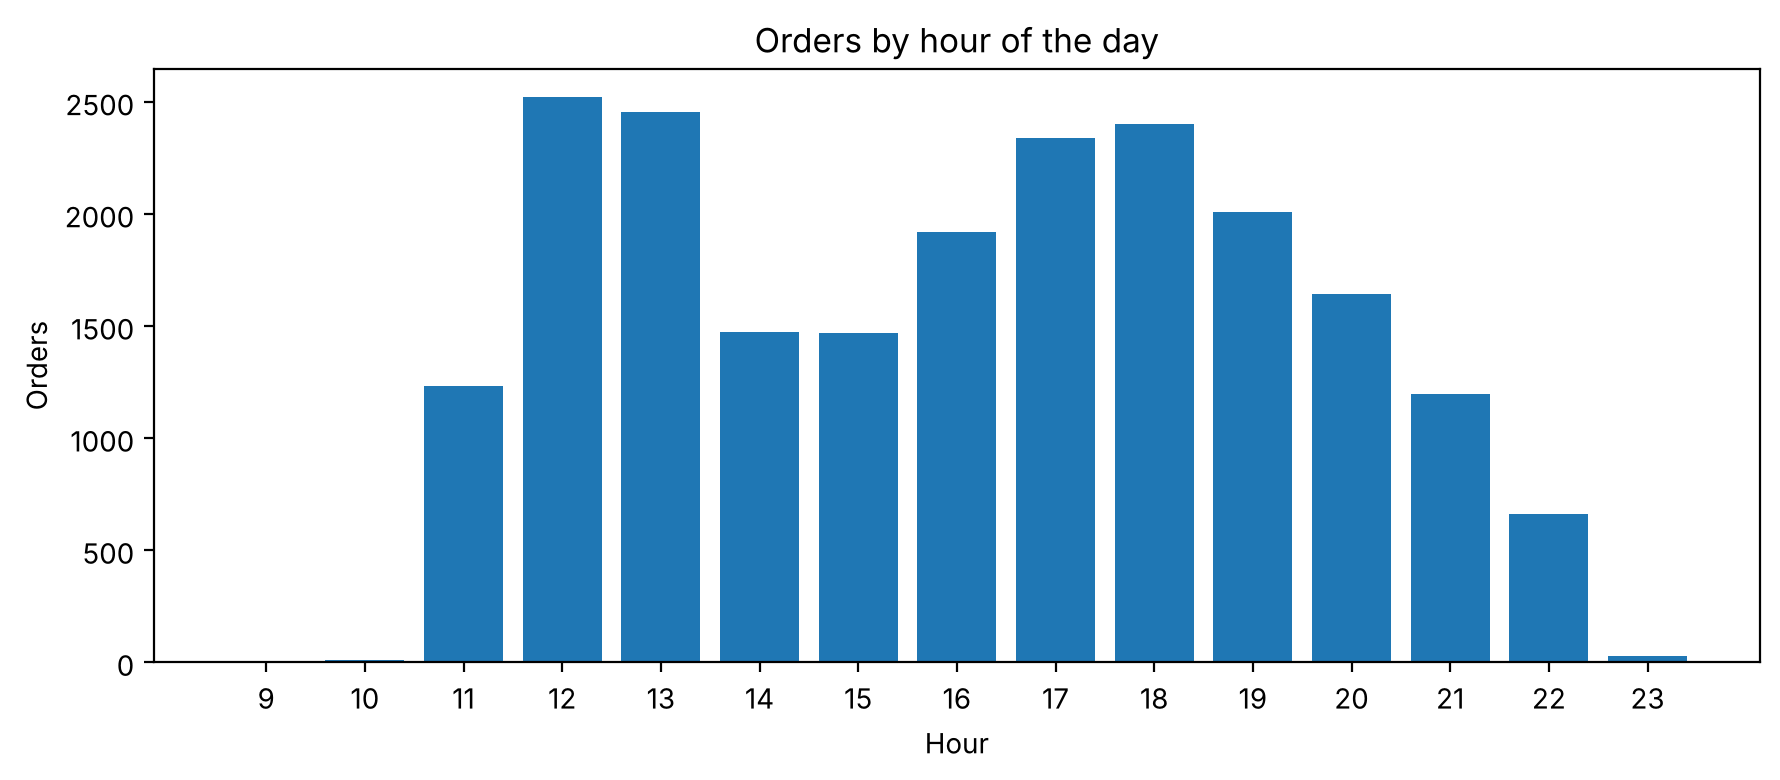

In [16]:
plt.figure(figsize=(9, 4))
plt.bar(hourly["hour"], hourly["orders"])
plt.title("Orders by hour of the day")
plt.xlabel("Hour")
plt.ylabel("Orders")
plt.xticks(hourly["hour"])
plt.tight_layout()
plt.savefig("orders_by_hour.png")
plt.show()

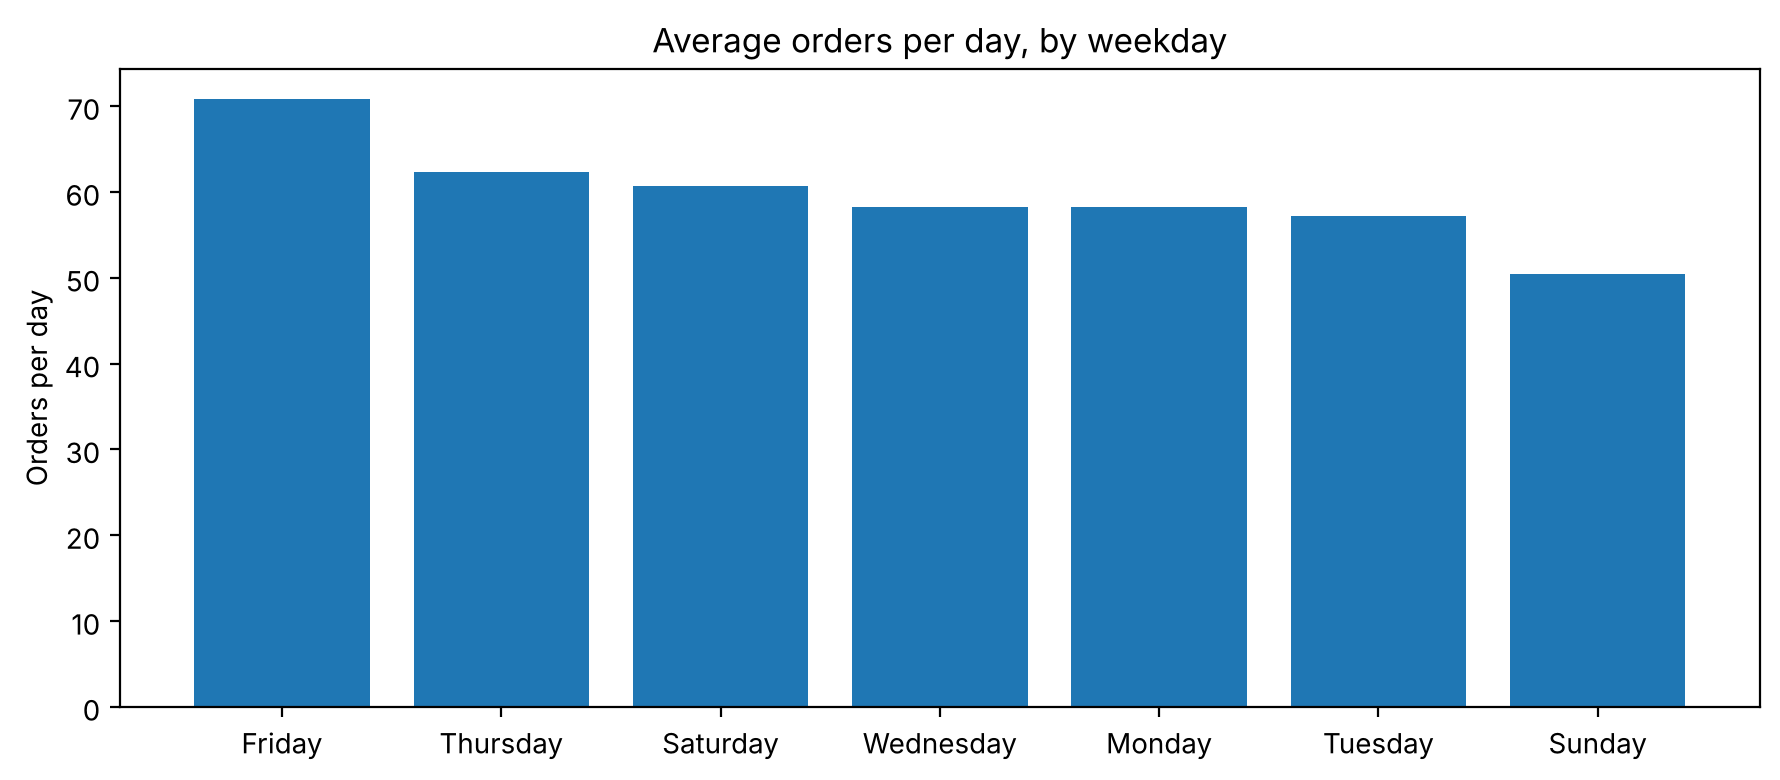

In [17]:
plt.figure(figsize=(9, 4))
plt.bar(weekday["weekday"], weekday["avg_orders_per_day"])
plt.title("Average orders per day, by weekday")
plt.ylabel("Orders per day")
plt.tight_layout()
plt.savefig("orders_by_weekday.png")
plt.show()

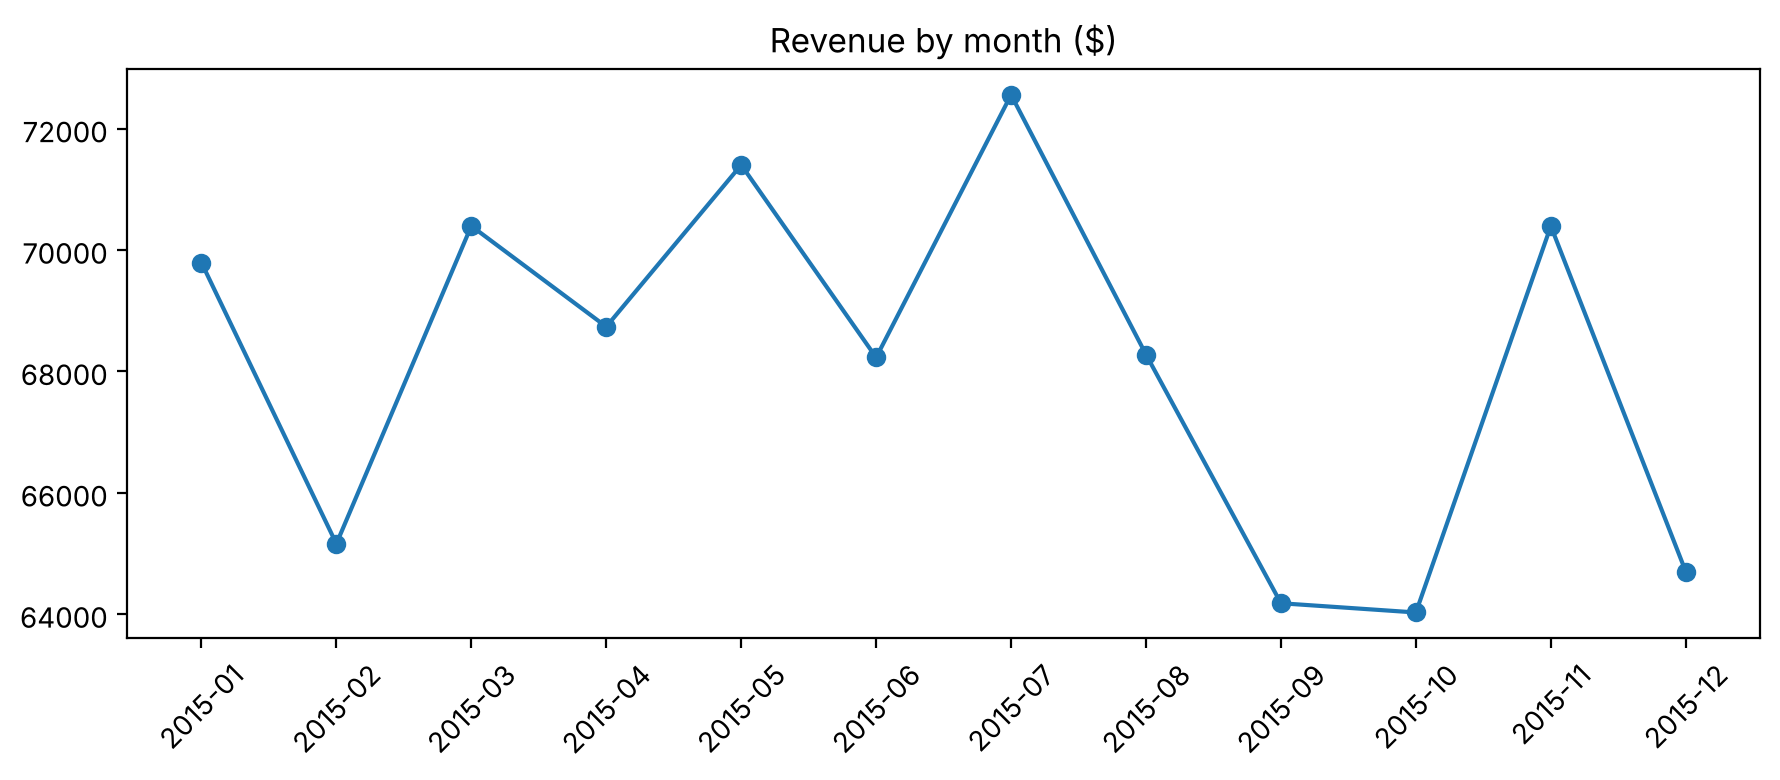

In [18]:
plt.figure(figsize=(9, 4))
plt.plot(monthly["month"], monthly["revenue"], marker="o")
plt.title("Revenue by month ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_revenue.png")
plt.show()

## Findings

- **$817,860** revenue from **21,350 orders** in 2015. An average order is **$38.31** with about **2.3 pizzas**.
- Sales are steady all year: no month is more than about 10% up or down from the month before.
- **Lunch (12 to 2 pm) is the busiest time**: 12 pm and 1 pm alone have 23% of all orders. There is a second peak at 5 to 7 pm.
- **Friday is the busiest day** (about 71 orders a day), and **Sunday the quietest** (about 51).
- **Large pizzas bring 46% of revenue.** XL and XXL together sell fewer than 600 pizzas in the whole year.
- The four categories are close in revenue (24% to 27% each).
- 20 of the 32 pizza types sell less than the average. The weakest is The Brie Carre Pizza.
- **38% of orders are a single pizza.**

## Recommendations
1. Put more staff on shift at lunch and from 5 to 7 pm, and on Fridays.
2. Review the bottom 5 pizzas: remove or replace the weakest ones to simplify the menu.
3. Consider dropping the XXL size, which sold only 28 pizzas in a year.
4. Offer a combo deal (second pizza or side at a discount) to grow the 38% of single-pizza orders.

## Limitations
- Only one year of data, so I can't measure year-on-year growth.
- There is no cost data, so I can't calculate profit.